# Proyek Analisis Data: [Bike Sharing Dataset]
- **Nama:** [Liza Arianti]
- **Email:** [ds898b6x0918@student.devacademy.id]
- **ID Dicoding:** [ds898b6x0918]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana pengaruh kondisi cuaca (weathersit) dan pergantian musim (season) terhadap rata-rata jumlah penyewaan sepeda harian (cnt) sepanjang tahun 2011 hingga 2012?
- **Pertanyaan 2:** Pada jam berapa (hr) terjadi puncak rata-rata penyewaan sepeda oleh pengguna terdaftar (registered) dibandingkan pengguna biasa (casual) saat hari kerja (workingday) versus hari libur selama tahun 2011 - 2012?


## Import Semua Packages/Library yang Digunakan

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## Data Wrangling

### Gathering Data

#### Load df bike sharing dataset

In [4]:
# Memuat dataset
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")

# Menampilkan 5 baris pertama
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- Dataset berhasil dimuat ke dalam dua DataFrame, yaitu day_df (berisi data penyewaan sepeda agregasi harian) dan hour_df (berisi data penyewaan agregasi per jam)
- Kedua dataset memiliki struktur kolom yang serupa, di mana kolom cnt merupakan total penyewaan sepeda yang berasal dari penjumlahan pengguna casual dan registered

### Assessing Data

#### Identifying Data Quality Problems

In [5]:
# 1. Memeriksa tipe data dan jumlah non-null
day_df.info()
hour_df.info()

# 2. Memeriksa missing value
print("Missing value day_df:\n", day_df.isna().sum())
print("\nMissing value hour_df:\n", hour_df.isna().sum())

# 3. Memeriksa duplikasi data
print("Jumlah duplikasi day_df:", day_df.duplicated().sum())
print("Jumlah duplikasi hour_df:", hour_df.duplicated().sum())

# 4. Memeriksa ringkasan parameter statistik (untuk melihat keanehan/outlier)
day_df.describe()
hour_df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (tot

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Steps to Take:**
- Menghapus kolom instant: Kolom ini hanya berisi nomor urut indeks baris yang tidak diperlukan dalam proses analisis.
- Mengubah tipe data kolom dteday: Mengonversi tipe data kolom dteday dari object (string) menjadi datetime agar sesuai untuk analisis berbasis waktu.
- Mengubah representasi angka menjadi label teks: Mengonversi kode angka pada kolom kategorikal (season, yr, weekday, dan weathersit) menjadi label teks deskriptif agar mudah dibaca pada saat visualisasi.

**Insight:** (Opsional)
- Dataset day_df terdiri dari 731 baris dengan 16 kolom, sedangkan hour_df terdiri dari 17.379 baris dengan 17 kolom
- Tidak ditemukan adanya missing value maupun duplicate data pada kedua dataset (bernilai 0 di seluruh kolom).
- Permasalahan kualitas data yang ditemukan adalah ketidaksesuaian tipe data pada kolom dteday (bertipe object) serta kolom kategori (season, yr, weekday, weathersit) yang masih berupa angka kode.

### Cleaning Data

#### Cleaning Data: Menghapus Kolom Tidak Relevan, Konversi Tipe Data, dan Mapping Kategori

In [6]:
# 1. Menghapus kolom 'instant' yang tidak diperlukan
day_df.drop(columns=['instant'], inplace=True)
hour_df.drop(columns=['instant'], inplace=True)

# 2. Mengubah tipe data 'dteday' menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 3. Mapping angka menjadi label teks agar mudah dibaca
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
yr_map = {0: 2011, 1: 2012}
weather_map = {
    1: 'Clear/Partly Cloudy',
    2: 'Mist/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Heavy Rain/Snow'
}
weekday_map = {
    0: 'Sunday', 1: 'Monday', 2: 'Tuesday', 3: 'Wednesday',
    4: 'Thursday', 5: 'Friday', 6: 'Saturday'
}

for df in [day_df, hour_df]:
    df['season'] = df['season'].map(season_map)
    df['yr'] = df['yr'].map(yr_map)
    df['weathersit'] = df['weathersit'].map(weather_map)
    df['weekday'] = df['weekday'].map(weekday_map)

# Verifikasi hasil cleaning
day_df.info()
day_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      731 non-null    datetime64[ns]
 1   season      731 non-null    object        
 2   yr          731 non-null    int64         
 3   mnth        731 non-null    int64         
 4   holiday     731 non-null    int64         
 5   weekday     731 non-null    object        
 6   workingday  731 non-null    int64         
 7   weathersit  731 non-null    object        
 8   temp        731 non-null    float64       
 9   atemp       731 non-null    float64       
 10  hum         731 non-null    float64       
 11  windspeed   731 non-null    float64       
 12  casual      731 non-null    int64         
 13  registered  731 non-null    int64         
 14  cnt         731 non-null    int64         
dtypes: datetime64[ns](1), float64(4), int64(7), object(3)
memory usage: 85.8+ 

,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,2011-01-01,Spring,2011,1,0,Saturday,0,Mist/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2011-01-02,Spring,2011,1,0,Sunday,0,Mist/Cloudy,0.363478,0.353739,0.696087,0.248539,131,670,801
2,2011-01-03,Spring,2011,1,0,Monday,1,Clear/Partly Cloudy,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,2011-01-04,Spring,2011,1,0,Tuesday,1,Clear/Partly Cloudy,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,2011-01-05,Spring,2011,1,0,Wednesday,1,Clear/Partly Cloudy,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- Kolom instant telah berhasil dihapus dari kedua DataFrame.
- Tipe data kolom dteday telah berubah menjadi datetime64
- Seluruh nilai pada kolom season, yr, weekday, dan weathersit kini sudah tampil dalam bentuk label teks yang jelas dan siap digunakan untuk tahap Exploratory Data Analysis (EDA)

## Exploratory Data Analysis (EDA)

### Explore 1: Menjawab Pertanyaan Bisnis 1 (Pengaruh Cuaca & Musim)

In [7]:
# Agregasi penyewaan harian berdasarkan Musim (season)
season_eda = day_df.groupby(by="season").agg({
    "cnt": ["count", "mean", "max", "min"],
    "casual": "mean",
    "registered": "mean"
}).sort_values(by=("cnt", "mean"), ascending=False)

print("=== Rata-rata Penyewaan Berdasarkan Musim ===")
print(season_eda)

# Agregasi penyewaan harian berdasarkan Kondisi Cuaca (weathersit)
weather_eda = day_df.groupby(by="weathersit").agg({
    "cnt": ["count", "mean", "max", "min"]
}).sort_values(by=("cnt", "mean"), ascending=False)

print("\n=== Rata-rata Penyewaan Berdasarkan Kondisi Cuaca ===")
print(weather_eda)

=== Rata-rata Penyewaan Berdasarkan Musim ===
         cnt                                casual   registered
       count         mean   max   min         mean         mean
season                                                         
Fall     188  5644.303191  8714  1115  1202.611702  4441.691489
Summer   184  4992.331522  8362   795  1106.097826  3886.233696
Winter   178  4728.162921  8555    22   729.112360  3999.050562
Spring   181  2604.132597  7836   431   334.928177  2269.204420

=== Rata-rata Penyewaan Berdasarkan Kondisi Cuaca ===
                      cnt                        
                    count         mean   max  min
weathersit                                       
Clear/Partly Cloudy   463  4876.786177  8714  431
Mist/Cloudy           247  4035.862348  8362  605
Light Snow/Rain        21  1803.285714  4639   22


**Insight:** (Opsional)
- Pengaruh Musim (season): Musim Gugur (Fall) mencatat rata-rata penyewaan harian tertinggi sebesar 5.644 penyewaan/hari (dengan rekor maksimal 8.714 penyewaan dalam sehari), diikuti oleh Musim Panas (Summer) sebesar 4.992 penyewaan/hari dan Musim Dingin (Winter) sebesar 4.728 penyewaan/hari. Sebaliknya, Musim Semi (Spring) memiliki rata-rata penyewaan paling rendah yaitu 2.604 penyewaan/hari
- Pengaruh Cuaca (weathersit): Mayoritas aktivitas penyewaan terjadi saat cuaca cerah/berawan sebagian (Clear/Partly Cloudy) dengan rata-rata 4.877 penyewaan/hari (total 463 hari). Saat cuaca berkabut/mendung (Mist/Cloudy), rata-rata turun menjadi 4.035 penyewaan/hari, dan merosot tajam hingga 1.803 penyewaan/hari saat terjadi hujan ringan atau salju ringan (Light Snow/Rain).

##Eksplorasi 2: Menjawab Pertanyaan Bisnis 2 (Pola Jam Sibuk: Registered vs Casual)

In [8]:
# Agregasi penyewaan per jam berdasarkan jam (hr) dan hari kerja (workingday)
hourly_eda = hour_df.groupby(by=["workingday", "hr"]).agg({
    "casual": "mean",
    "registered": "mean",
    "cnt": "mean"
}).reset_index()

print("=== Rata-rata Penyewaan Per Jam (Workingday: 1 vs Weekend/Holiday: 0) ===")
print(hourly_eda.head(24))

# Melihat jam puncak tertinggi untuk masing-masing tipe pengguna
print("\n=== Top 5 Jam Puncak Pengguna Registered ===")
print(hour_df.groupby("hr")["registered"].mean().sort_values(ascending=False).head(5))

print("\n=== Top 5 Jam Puncak Pengguna Casual ===")
print(hour_df.groupby("hr")["casual"].mean().sort_values(ascending=False).head(5))

=== Rata-rata Penyewaan Per Jam (Workingday: 1 vs Weekend/Holiday: 0) ===
    workingday  hr      casual  registered         cnt
0            0   0   16.647826   74.152174   90.800000
1            0   1   12.504348   57.004348   69.508696
2            0   2   10.399123   42.771930   53.171053
3            0   3    6.453744   19.321586   25.775330
4            0   4    2.264317    6.000000    8.264317
5            0   5    1.725225    6.963964    8.689189
6            0   6    3.820961   14.921397   18.742358
7            0   7    8.606061   34.800866   43.406926
8            0   8   20.424242   85.229437  105.653680
9            0   9   45.017316  126.606061  171.623377
10           0  10   79.268398  176.640693  255.909091
11           0  11  106.653680  208.662338  315.316017
12           0  12  126.246753  240.012987  366.259740
13           0  13  136.424242  236.307359  372.731602
14           0  14  139.593074  225.051948  364.645022
15           0  15  136.502165  222.311688  35

**Insight:** (Opsional)
- Puncak Penyewaan Pengguna Registered: Secara keseluruhan, penyewaan tertinggi oleh pengguna terdaftar terjadi pada jam pulang kerja yaitu pukul 17:00 (rata-rata 387,18 penyewaan/jam) dan pukul 18:00 (364,39 penyewaan/jam), serta pada jam berangkat kerja pukul 08:00 (337,33 penyewaan/jam).
- Puncak Penyewaan Pengguna Casual: Berbeda dengan pengguna terdaftar, penyewaan pengguna biasa justru memuncak pada siang hingga sore hari untuk aktivitas santai/rekreasi, yaitu pada pukul 14:00 (rata-rata 75,57 penyewaan/jam), pukul 15:00 (74,91 penyewaan/jam), dan pukul 17:00 (74,27 penyewaan/jam).
- Perbedaan Pola Hari Libur (workingday == 0): Pada tabel agregasi saat akhir pekan/hari libur (workingday = 0), tidak terlihat lonjakan pada pukul 08:00 pagi; aktivitas penyewaan baru meningkat bertahap mulai pukul 09:00 dan mencapai puncak tertingginya pada siang hari pukul 13:00 dengan rata-rata total 372,73 penyewaan/jam.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Visualisasi 1: Menjawab Pertanyaan Bisnis 1 (Pengaruh Musim & Cuaca)

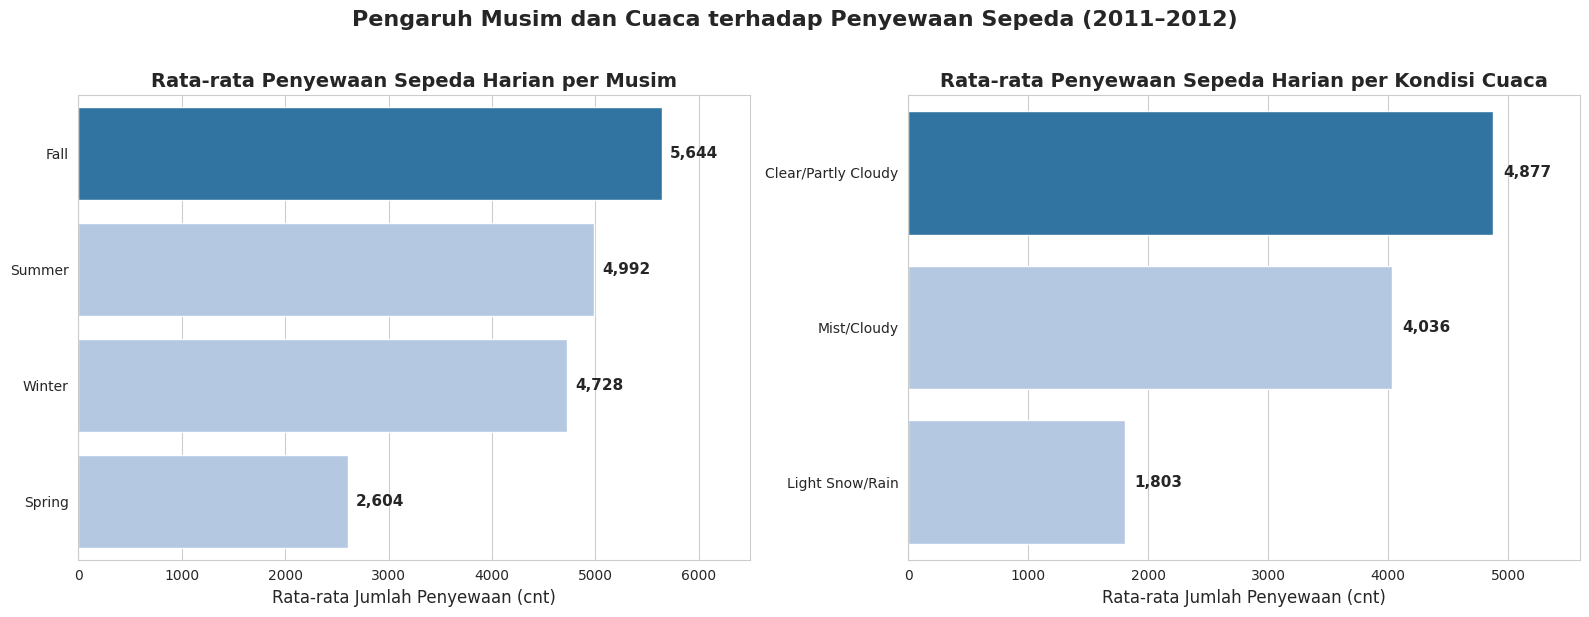

In [9]:
# Mengatur gaya visualisasi
sns.set_style("whitegrid")
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# --- Grafik 1A: Rata-rata Penyewaan Berdasarkan Musim ---
season_avg = day_df.groupby("season")["cnt"].mean().sort_values(ascending=False).reset_index()
colors_season = ["#1f77b4", "#aec7e8", "#aec7e8", "#aec7e8"] # Highlight bar tertinggi

sns.barplot(
    x="cnt", y="season", data=season_avg, palette=colors_season, ax=ax[0], hue="season", legend=False
)
ax[0].set_title("Rata-rata Penyewaan Sepeda Harian per Musim", fontsize=14, fontweight="bold")
ax[0].set_xlabel("Rata-rata Jumlah Penyewaan (cnt)", fontsize=12)
ax[0].set_ylabel(None)
for index, value in enumerate(season_avg["cnt"]):
    ax[0].text(value + 80, index, f"{value:,.0f}", va="center", fontsize=11, fontweight="bold")
ax[0].set_xlim(0, 6500)

# --- Grafik 1B: Rata-rata Penyewaan Berdasarkan Kondisi Cuaca ---
weather_avg = day_df.groupby("weathersit")["cnt"].mean().sort_values(ascending=False).reset_index()
colors_weather = ["#1f77b4", "#aec7e8", "#aec7e8"]

sns.barplot(
    x="cnt", y="weathersit", data=weather_avg, palette=colors_weather, ax=ax[1], hue="weathersit", legend=False
)
ax[1].set_title("Rata-rata Penyewaan Sepeda Harian per Kondisi Cuaca", fontsize=14, fontweight="bold")
ax[1].set_xlabel("Rata-rata Jumlah Penyewaan (cnt)", fontsize=12)
ax[1].set_ylabel(None)
for index, value in enumerate(weather_avg["cnt"]):
    ax[1].text(value + 80, index, f"{value:,.0f}", va="center", fontsize=11, fontweight="bold")
ax[1].set_xlim(0, 5600)

plt.suptitle("Pengaruh Musim dan Cuaca terhadap Penyewaan Sepeda (2011–2012)", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### Pertanyaan 2:
Visualisasi 2: Menjawab Pertanyaan Bisnis 2 (Pola Jam Sibuk: Registered vs Casual)

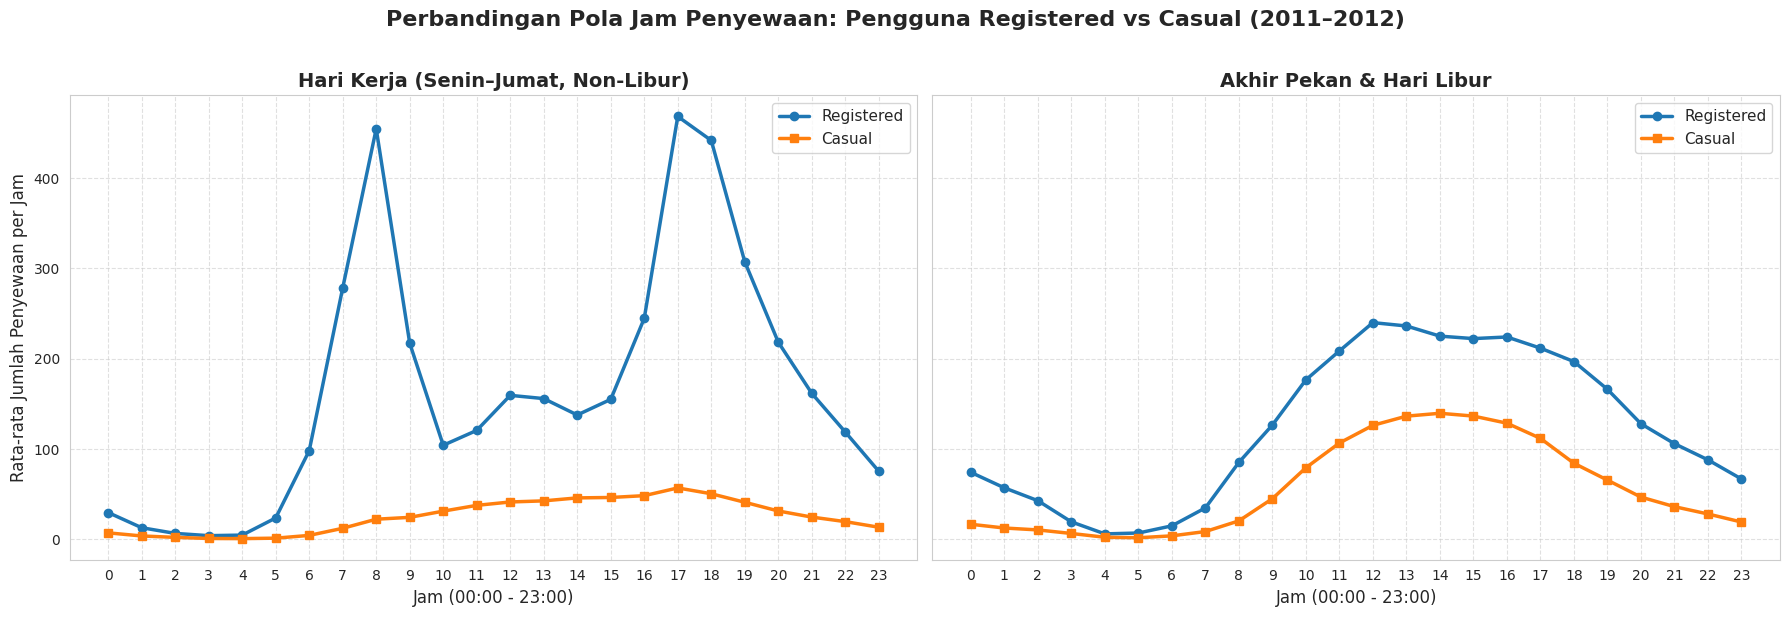

In [10]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 6), sharey=True)

# Filter data hari kerja (workingday == 1) dan hari libur/akhir pekan (workingday == 0)
working_df = hour_df[hour_df["workingday"] == 1].groupby("hr")[["registered", "casual"]].mean().reset_index()
holiday_df = hour_df[hour_df["workingday"] == 0].groupby("hr")[["registered", "casual"]].mean().reset_index()

# --- Grafik 2A: Pola Jam Sibuk pada Hari Kerja (Workingday) ---
ax[0].plot(working_df["hr"], working_df["registered"], marker="o", linewidth=2.5, color="#1f77b4", label="Registered")
ax[0].plot(working_df["hr"], working_df["casual"], marker="s", linewidth=2.5, color="#ff7f0e", label="Casual")
ax[0].set_title("Hari Kerja (Senin–Jumat, Non-Libur)", fontsize=14, fontweight="bold")
ax[0].set_xlabel("Jam (00:00 - 23:00)", fontsize=12)
ax[0].set_ylabel("Rata-rata Jumlah Penyewaan per Jam", fontsize=12)
ax[0].set_xticks(range(0, 24))
ax[0].legend(fontsize=11)
ax[0].grid(True, linestyle="--", alpha=0.6)

# --- Grafik 2B: Pola Jam Sibuk pada Akhir Pekan & Hari Libur ---
ax[1].plot(holiday_df["hr"], holiday_df["registered"], marker="o", linewidth=2.5, color="#1f77b4", label="Registered")
ax[1].plot(holiday_df["hr"], holiday_df["casual"], marker="s", linewidth=2.5, color="#ff7f0e", label="Casual")
ax[1].set_title("Akhir Pekan & Hari Libur", fontsize=14, fontweight="bold")
ax[1].set_xlabel("Jam (00:00 - 23:00)", fontsize=12)
ax[1].set_xticks(range(0, 24))
ax[1].legend(fontsize=11)
ax[1].grid(True, linestyle="--", alpha=0.6)

plt.suptitle("Perbandingan Pola Jam Penyewaan: Pengguna Registered vs Casual (2011–2012)", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Insight Visualisasi 1 (Musim & Cuaca): Grafik batang menunjukkan bahwa permintaan penyewaan sepeda sangat dipengaruhi oleh kenyamanan cuaca dan musim. Musim Gugur (Fall) menjadi musim paling diminati dengan rata-rata 5.644 penyewaan/hari, sedangkan Musim Semi (Spring) mencatat rata-rata terendah (2.604 penyewaan/hari). Dari sisi cuaca, kondisi cerah/berawan sebagian (Clear/Partly Cloudy) menghasilkan rata-rata penyewaan tertinggi (4.877 penyewaan/hari), namun permintaan turun drastis hingga lebih dari 63% menjadi 1.803 penyewaan/hari saat cuaca hujan ringan atau salju ringan (Light Snow/Rain)
- Insight Visualisasi 2 (Pola Jam Sibuk): Grafik garis memperlihatkan perbedaan perilaku yang kontras antara hari kerja dan hari libur. Pada hari kerja, pengguna Registered membentuk dua puncak tajam (bimodal) pada pukul 08:00 pagi dan 17:00–18:00 sore yang mencerminkan rutinitas berangkat dan pulang kerja/sekolah. Sebaliknya, pada akhir pekan dan hari libur, pola penyewaan bergeser menjadi satu kurva landai di siang hari (puncak pukul 12:00–15:00), di mana volume penyewaan pengguna Casual meningkat signifikan untuk kebutuhan rekreasi.

## Analisis Lanjutan (Opsional)

              Kategori Waktu  Total Penyewaan  Rata-rata per Jam  \
4       Sore (17:00 - 20:00)          1037971         356.201441   
3      Siang (12:00 - 16:00)           955882         262.244719   
2       Pagi (06:00 - 11:00)           907319         208.100688   
1      Malam (21:00 - 23:00)           284998         130.493590   
0  Dini Hari (00:00 - 05:00)           106509          24.908559   

   Total Casual  Total Registered  
4        160599            877372  
3        265960            689922  
2        126348            780971  
1         47835            237163  
0         19275             87234  


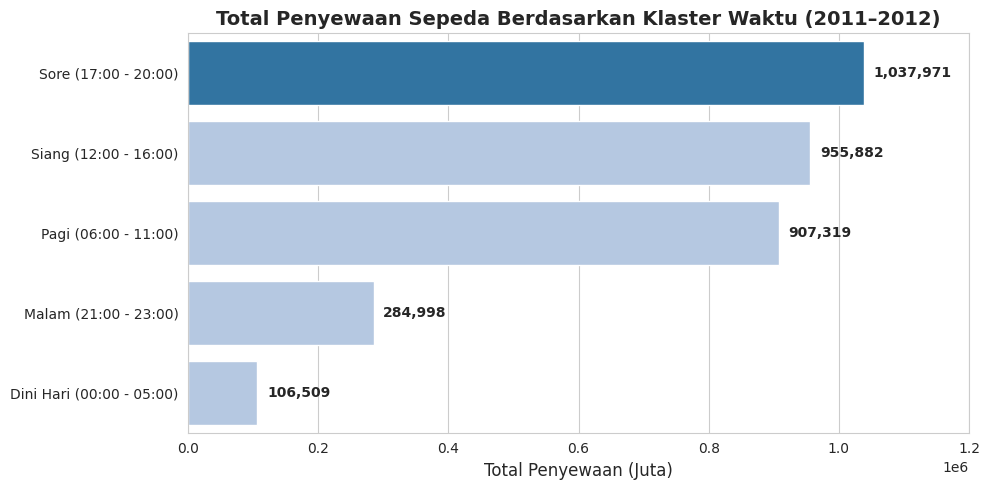

In [11]:
# Teknik Analisis Lanjutan: Manual Grouping / Binning berdasarkan Kategori Waktu
def categorize_time(hr):
    if 0 <= hr <= 5:
        return "Dini Hari (00:00 - 05:00)"
    elif 6 <= hr <= 11:
        return "Pagi (06:00 - 11:00)"
    elif 12 <= hr <= 16:
        return "Siang (12:00 - 16:00)"
    elif 17 <= hr <= 20:
        return "Sore (17:00 - 20:00)"
    else:
        return "Malam (21:00 - 23:00)"

# Membuat kolom baru 'time_category' pada hour_df
hour_df["time_category"] = hour_df["hr"].apply(categorize_time)

# Agregasi total dan rata-rata penyewaan per kategori waktu
time_cluster = hour_df.groupby("time_category").agg({
    "cnt": ["sum", "mean"],
    "casual": "sum",
    "registered": "sum"
}).reset_index()

# Merapikan nama kolom
time_cluster.columns = ["Kategori Waktu", "Total Penyewaan", "Rata-rata per Jam", "Total Casual", "Total Registered"]
time_cluster = time_cluster.sort_values(by="Total Penyewaan", ascending=False)

print(time_cluster)

# Visualisasi Hasil Clustering Waktu
plt.figure(figsize=(10, 5))
colors = ["#1f77b4", "#aec7e8", "#aec7e8", "#aec7e8", "#aec7e8"]

sns.barplot(
    x="Total Penyewaan",
    y="Kategori Waktu",
    data=time_cluster,
    palette=colors,
    hue="Kategori Waktu",
    legend=False
)
plt.title("Total Penyewaan Sepeda Berdasarkan Klaster Waktu (2011–2012)", fontsize=14, fontweight="bold")
plt.xlabel("Total Penyewaan (Juta)", fontsize=12)
plt.ylabel(None)

for index, value in enumerate(time_cluster["Total Penyewaan"]):
    plt.text(value + 15000, index, f"{value:,.0f}", va="center", fontsize=10, fontweight="bold")

plt.xlim(0, 1200000)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Dominasi Waktu Sore & Siang: Klaster waktu Sore (17:00 - 20:00) menyumbang volume penyewaan tertinggi secara keseluruhan dengan total 1.037.971 penyewaan (rata-rata 356 penyewaan/jam), disusul oleh waktu Siang (12:00 - 16:00) dengan total 955.882 penyewaan
- Perbedaan Karakteristik Segmen per Klaster: Pengguna Registered mendominasi klaster waktu Sore (877.372 penyewaan) dan Pagi (780.971 penyewaan) yang berkaitan erat dengan mobilitas komuter. Sebaliknya, pengguna Casual mencapai puncaknya pada klaster waktu Siang (265.960 penyewaan), menunjukkan preferensi penggunaan sepeda untuk aktivitas santai atau wisata di tengah hari.
- Waktu Sepi untuk Operasional: Klaster Dini Hari (00:00 - 05:00) memiliki aktivitas paling minim (rata-rata hanya 25 penyewaan/jam), menjadikannya jendela waktu paling ideal untuk melakukan pengisian ulang (rebalancing) distribusi sepeda antar stasiun tanpa mengganggu pelanggan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:**
- Musim: Rata-rata penyewaan sepeda harian tertinggi terjadi pada Musim Gugur (Fall) sebesar 5.644 penyewaan/hari, diikuti oleh Musim Panas (Summer) sebesar 4.992 penyewaan/hari, dan Musim Dingin (Winter) sebesar 4.728 penyewaan/hari. Penyewaan terendah terjadi pada Musim Semi (Spring) dengan rata-rata hanya 2.604 penyewaan/hari (turun lebih dari 53% dibandingkan Musim Gugur).
-  Kondisi Cuaca: Cuaca cerah atau berawan sebagian (Clear/Partly Cloudy) mencatat rata-rata penyewaan tertinggi sebesar 4.877 penyewaan/hari. Ketika cuaca berubah menjadi berkabut/mendung (Mist/Cloudy), penyewaan turun menjadi 4.036 penyewaan/hari, dan anjlok drastis hingga 1.803 penyewaan/hari saat hujan ringan atau salju ringan (Light Snow/Rain). Sepanjang 2011–2012, tidak ada catatan penyewaan harian rata-rata pada cuaca ekstrem (Heavy Rain/Snow).
- **Conclusion pertanyaan 2:**
- Pada Hari Kerja (Workingday): Pengguna Registered mendominasi secara signifikan dengan pola bimodal (dua puncak tajam) pada jam komuter, yaitu pukul 08:00 pagi (rata-rata 455 penyewaan/jam) saat berangkat kerja/sekolah, serta pukul 17:00–18:00 sore (puncak 468 penyewaan/jam pada pukul 17:00) saat jam pulang kerja. Sementara itu, pengguna Casual cenderung rendah sepanjang hari kerja dengan puncak kecil di pukul 17:00 (57 penyewaan/jam).
- Pada Akhir Pekan & Hari Libur: Pola berubah menjadi unimodal (satu puncak landai di siang hari) untuk kedua segmen. Penyewaan pengguna Registered memuncak pada pukul 12:00–14:00 siang (rata-rata 240 penyewaan/jam pada pukul 12:00), sedangkan pengguna Casual melonjak hampir 2,5 kali lipat dibandingkan hari kerja dengan puncak aktivitas rekreasi pada pukul 13:00–15:00 siang (puncak 140 penyewaan/jam pada pukul 14:00).

**Rekomendasi Action Item:**
- Optimalisasi Redistribusi & Ketersediaan Armada (Operasional):
Pada hari kerja, tim operasional lapangan harus memastikan stasiun sepeda di area pemukiman dan titik transit transportasi publik terisi penuh sebelum pukul 07:30 pagi, serta memindahkan kembali stok sepeda ke area perkantoran sebelum pukul 16:30 sore untuk mengantisipasi lonjakan pengguna registered.
- Penjadwalan Pemeliharaan Rutin (Preventive Maintenance): Manfaatkan periode Musim Semi (Spring)—yang memiliki volume penyewaan terendah—untuk melakukan perbaikan besar, pengecatan ulang, dan perawatan menyeluruh pada armada sepeda agar seluruh unit siap beroperasi 100% saat memasuki puncak permintaan di Musim Panas dan Musim Gugur.
- Strategi Konversi Pelanggan (Marketing Campaign): Jalankan kampanye promosi berlangganan (membership pass akhir pekan atau diskon pendaftaran pertama) yang ditargetkan khusus pada akhir pekan pukul 11:00–15:00 di stasiun-stasiun area wisata/taman kota untuk mengonversi pengguna casual menjadi pelanggan registered.